# PovertyRadar SDGs
## 01. Data Audit, Data Understanding, & Anomaly Profiling

**Proyek:** Sistem Pemetaan Klaster dan Skrining Kerentanan Kemiskinan Daerah Indonesia  
**Mata Kuliah:** Presentasi Data dan Storytelling  
**Fokus SDGs:** Goal 1 — *No Poverty* (Tanpa Kemiskinan)  
**Dataset:** [Klasifikasi Tingkat Kemiskinan di Indonesia (Kaggle Dataset oleh ldausl / BPS 2021)](https://www.kaggle.com/datasets/ldausl/klasifikasi-tingkat-kemiskinan-di-indonesia)

---

### Tujuan & Ruang Lingkup Notebook:
1. **Pemeriksaan Integritas Teknis:** Memvalidasi struktur file, tipe data, spasi tersembunyi (*trailing whitespace*), dan karakter anomali.
2. **Audit Kualitas Data:** Mendeteksi nilai *missing* (eksplisit & implisit), duplikasi baris/wilayah, serta nilai batas nol (*true boundary zero* di wilayah 3T Papua).
3. **Statistik Deskriptif & Deteksi Outlier (Univariat):** Menghitung sebaran, kemencengan (*skewness*), dan mengidentifikasi wilayah *outlier* spesifik menggunakan kriteria $1.5 \times \text{IQR}$.
4. **Deteksi Anomali Multivariat (*Isolation Forest*):** Mengidentifikasi wilayah dengan kombinasi indikator yang tidak lazim (*enclave economies* dan disparitas multidimensi) serta visualisasi proyeksi PCA.
5. **Kebijakan Penanganan Outlier (*Outlier Policy*):** Menetapkan justifikasi ilmiah mengapa outlier dipertahankan (*do not drop*) dan menyiapkan mitigasi *scaling* yang kebal pencilan (`RobustScaler`).
6. **Analisis Multidimensi & Multikolinearitas:** Menelaah korelasi antar-indikator (redundansi IPM), fenomena ketenagakerjaan, serta disparitas perkotaan-perdesaan dan antarpulau.
7. **Audit Kritis Fitur Target (`Klasifikasi Kemiskinan`):** Menunjukkan mengapa label biner bawaan diabaikan sepenuhnya (**No Supervised Classification**).
8. **Data Preparation & Export:** Menyimpan dataset interim yang telah diperkaya skor anomali ke `data/interim/poverty_data_cleaned.csv`.

In [1]:
# 1. Imports & Configuration
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

# Set random seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

# Project-relative paths
BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == 'notebooks':
    BASE_DIR = BASE_DIR.parent

RAW_DATA_PATH = BASE_DIR / 'data' / 'raw' / 'Klasifikasi Tingkat Kemiskinan di Indonesia.csv'
INTERIM_DATA_DIR = BASE_DIR / 'data' / 'interim'
INTERIM_DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_DATA_PATH = INTERIM_DATA_DIR / 'poverty_data_cleaned.csv'

print(f"Base Directory: {BASE_DIR}")
print(f"Raw Data Path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")

Base Directory: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar
Raw Data Path: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\data\raw\Klasifikasi Tingkat Kemiskinan di Indonesia.csv (Exists: True)


---
## 2. Ingesti Data & Audit Teknis

Memeriksa struktur file CSV mentah, penamaan kolom asli, dan adanya spasi tersembunyi (*trailing whitespace*) atau karakter anomali.

In [2]:
# 2. Ingesti data awal
df_raw = pd.read_csv(RAW_DATA_PATH)
print(f"Bentuk data mentah (Baris, Kolom): {df_raw.shape}")
print("\nTipe data per kolom:")
print(df_raw.dtypes)

Bentuk data mentah (Baris, Kolom): (514, 13)

Tipe data per kolom:
Provinsi                                                                 object
Kab/Kota                                                                 object
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)         float64
Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                             float64
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)              int64
Indeks Pembangunan Manusia                                              float64
Umur Harapan Hidup (Tahun)                                              float64
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak     float64
Persentase rumah tangga yang memiliki akses terhadap air minum layak    float64
Tingkat Pengangguran Terbuka                                            float64
Tingkat Partisipasi Angkatan Kerja                                      float64
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Ru

In [3]:
# Pemeriksaan spasi tersembunyi (trailing/leading whitespace)
str_cols = df_raw.select_dtypes(include='object').columns
whitespace_issues = {}

for col in str_cols:
    has_space = df_raw[col].astype(str).str.contains(r'^\s+|\s+$').any()
    if has_space:
        whitespace_issues[col] = df_raw[col][df_raw[col].astype(str).str.contains(r'^\s+|\s+$')].head(3).tolist()

print("Kolom dengan masalah whitespace:")
for k, v in whitespace_issues.items():
    print(f"  - Kolom '{k}': contoh nilai {v}")

# Pemeriksaan karakter khusus pada nama Kab/Kota (residu footnote BPS)
special_char_rows = df_raw[df_raw['Kab/Kota'].str.contains(r'[^a-zA-Z0-9\s\.\,\-]', regex=True)]
print(f"\nBaris dengan karakter khusus pada nama wilayah: {len(special_char_rows)}")
if len(special_char_rows) > 0:
    print(special_char_rows[['Provinsi', 'Kab/Kota']])

Kolom dengan masalah whitespace:

Baris dengan karakter khusus pada nama wilayah: 1
    Provinsi Kab/Kota
505    PAPUA  Nduga *


---
## 3. Data Cleaning & Normalization Pipeline

Pipeline standardisasi teknis:
1. Menghapus *trailing/leading whitespace* dari seluruh kolom dan nama header.
2. Membersihkan karakter footnote asterisk `*` pada entitas wilayah (`Nduga *` $\rightarrow$ `Nduga`).
3. Mengonversi kolom numerik yang sempat terbaca sebagai string/object.
4. Memberikan alias kolom terstandar (*snake_case*) untuk kemudahan komputasi.

In [4]:
# 3. Pipeline Pembersihan Teknis
df = df_raw.copy()

# Strip whitespace pada nama kolom
df.columns = df.columns.str.strip()

# Strip whitespace pada seluruh data teks
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()

# Bersihkan karakter asterisk pada nama Kab/Kota
df['Kab/Kota'] = df['Kab/Kota'].str.replace('*', '', regex=False).str.strip()

# Konversi kolom numerik yang sempat terbaca string
numeric_candidates = [c for c in df.columns if c not in ['Provinsi', 'Kab/Kota']]
for col in numeric_candidates:
    df[col] = pd.to_numeric(df[col])

# Definisi nama kolom terstandar (English/Snake-Case Friendly)
COLUMN_MAP = {
    'Provinsi': 'provinsi',
    'Kab/Kota': 'kab_kota',
    'Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)': 'poverty_rate_p0',
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)': 'avg_school_years',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)': 'expenditure_per_capita',
    'Indeks Pembangunan Manusia': 'human_dev_index',
    'Umur Harapan Hidup (Tahun)': 'life_expectancy',
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak': 'sanitation_access_pct',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak': 'clean_water_access_pct',
    'Tingkat Pengangguran Terbuka': 'unemployment_rate_tpt',
    'Tingkat Partisipasi Angkatan Kerja': 'labor_participation_tpak',
    'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)': 'grdp_constant_million_idr',
    'Klasifikasi Kemiskinan': 'poverty_class_target'
}

df_renamed = df.rename(columns=COLUMN_MAP)
print(f"Dataframe berhasil dibersihkan! Dimensi: {df_renamed.shape}")
df_renamed.head()

Dataframe berhasil dibersihkan! Dimensi: (514, 13)


,provinsi,kab_kota,poverty_rate_p0,avg_school_years,expenditure_per_capita,human_dev_index,life_expectancy,sanitation_access_pct,clean_water_access_pct,unemployment_rate_tpt,labor_participation_tpak,grdp_constant_million_idr,poverty_class_target
0,ACEH,Simeulue,18.980,9.480,7148,66.410,65.280,71.560,87.450,5.710,71.150,1648096,0
1,ACEH,Aceh Singkil,20.360,8.680,8776,69.220,67.430,69.560,78.580,8.360,62.850,1780419,1
2,ACEH,Aceh Selatan,13.180,8.880,8180,67.440,64.400,62.550,79.650,6.460,60.850,4345784,0
3,ACEH,Aceh Tenggara,13.410,9.670,8030,69.440,68.220,62.710,86.710,6.430,69.620,3487157,0
4,ACEH,Aceh Timur,14.450,8.210,8577,67.830,68.740,66.750,83.160,7.130,59.480,8433526,0


---
## 4. Audit Integritas Data (Missing Values, Duplikasi, Zero-Checks)

Memeriksa kelengkapan nilai, duplikasi record, serta mengonfirmasi kontekstual nilai 0.00% pada fasilitas dasar dan pengangguran.

In [5]:
# 4.1 Missing values check
missing_summary = df_renamed.isnull().sum()
print("Jumlah Missing Values (NaN):")
print(missing_summary[missing_summary > 0] if (missing_summary > 0).any() else ">> TIDAK DITEMUKAN MISSING VALUE (0 missing across all features)")

# 4.2 Duplicate check
dup_rows = df_renamed.duplicated().sum()
dup_entities = df_renamed.duplicated(subset=['provinsi', 'kab_kota']).sum()
print(f"\nDuplikasi baris penuh: {dup_rows}")
print(f"Duplikasi entitas (provinsi, kab_kota): {dup_entities}")

# 4.3 Zero values check
print("\nPemeriksaan nilai 0.00% pada variabel numerik:")
for col in df_renamed.select_dtypes(include=[np.number]).columns:
    zero_cnt = (df_renamed[col] == 0).sum()
    if zero_cnt > 0 and col != 'poverty_class_target':
        zero_regions = df_renamed[df_renamed[col] == 0][['provinsi', 'kab_kota', col]]
        print(f"  - Kolom '{col}': {zero_cnt} wilayah bernilai nol:")
        for _, r in zero_regions.iterrows():
            print(f"      * {r['kab_kota']} ({r['provinsi']}) = 0")

Jumlah Missing Values (NaN):
>> TIDAK DITEMUKAN MISSING VALUE (0 missing across all features)

Duplikasi baris penuh: 0
Duplikasi entitas (provinsi, kab_kota): 0

Pemeriksaan nilai 0.00% pada variabel numerik:
  - Kolom 'sanitation_access_pct': 1 wilayah bernilai nol:
      * Deiyai (PAPUA) = 0
  - Kolom 'clean_water_access_pct': 1 wilayah bernilai nol:
      * Mamberamo Tengah (PAPUA) = 0
  - Kolom 'unemployment_rate_tpt': 2 wilayah bernilai nol:
      * Nduga (PAPUA) = 0
      * Lanny Jaya (PAPUA) = 0


---
## 5. Profiling Statistik, Deteksi Outliers, & Anomali Multivariat

Menganalisis sebaran pemusatan, kemencengan (*skewness*), pencilan univariat ($1.5 \times \text{IQR}$), serta deteksi anomali gabungan (*multivariate anomalies*) menggunakan algoritma **Isolation Forest**.

In [6]:
# 5.1 Ringkasan Statistik Deskriptif & Outlier Summary (Tukey IQR)
numeric_cols = [c for c in df_renamed.select_dtypes(include=[np.number]).columns if c != 'poverty_class_target']

stats_records = []
for c in numeric_cols:
    q1 = df_renamed[c].quantile(0.25)
    q3 = df_renamed[c].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = len(df_renamed[(df_renamed[c] < lower) | (df_renamed[c] > upper)])
    
    stats_records.append({
        'Feature': c,
        'Mean': df_renamed[c].mean(),
        'Std': df_renamed[c].std(),
        'Min': df_renamed[c].min(),
        'Q1 (25%)': q1,
        'Median (50%)': df_renamed[c].median(),
        'Q3 (75%)': q3,
        'Max': df_renamed[c].max(),
        'Skewness': df_renamed[c].skew(),
        'N Outliers': n_out,
        'Pct Outliers (%)': (n_out / len(df_renamed)) * 100
    })

stats_df = pd.DataFrame(stats_records)
stats_df.set_index('Feature')

,Mean,Std,Min,Q1 (25%),Median (50%),Q3 (75%),Max,Skewness,N Outliers,Pct Outliers (%)
Feature,,,,,,,,,,
poverty_rate_p0,12.273,7.459,2.380,7.150,10.455,14.888,41.660,1.505,36,7.004
avg_school_years,8.437,1.631,1.420,7.510,8.305,9.338,12.830,-0.353,14,2.724
expenditure_per_capita,10324.788,2717.144,3976.000,8574.000,10196.500,11719.000,23888.000,0.732,15,2.918
human_dev_index,69.927,6.497,32.840,66.642,69.610,73.113,87.180,-0.781,27,5.253
life_expectancy,69.657,3.447,55.430,67.387,69.975,72.042,77.730,-0.469,8,1.556
sanitation_access_pct,77.202,18.584,0.000,70.218,81.800,89.882,99.970,-1.822,25,4.864
clean_water_access_pct,85.137,15.702,0.000,79.042,89.795,96.400,100.000,-2.039,23,4.475
unemployment_rate_tpt,5.059,2.637,0.000,3.180,4.565,6.530,13.370,0.790,12,2.335
labor_participation_tpak,69.464,6.396,56.390,65.070,68.955,72.343,97.930,1.187,20,3.891


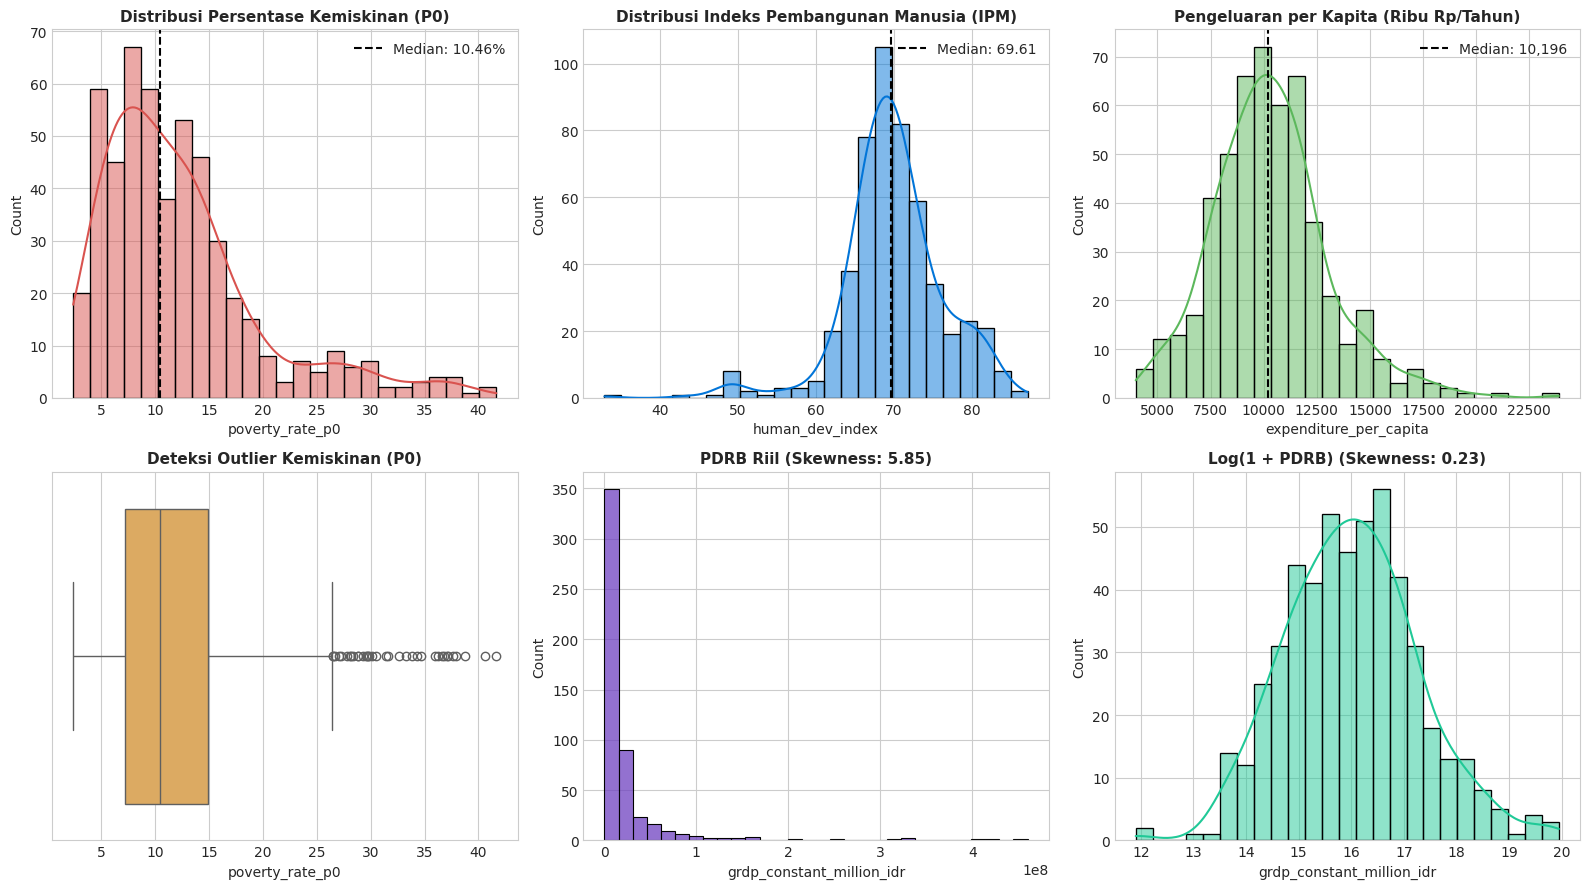

In [7]:
# 5.2 Visualisasi Distribusi: Kemiskinan (P0), IPM, dan PDRB
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Poverty Rate P0
sns.histplot(df_renamed['poverty_rate_p0'], kde=True, ax=axes[0, 0], color='#d9534f', bins=25)
axes[0, 0].set_title('Distribusi Persentase Kemiskinan (P0)', fontsize=11, fontweight='bold')
axes[0, 0].axvline(df_renamed['poverty_rate_p0'].median(), color='black', linestyle='--', label=f"Median: {df_renamed['poverty_rate_p0'].median():.2f}%")
axes[0, 0].legend()

# 2. Human Development Index
sns.histplot(df_renamed['human_dev_index'], kde=True, ax=axes[0, 1], color='#0275d8', bins=25)
axes[0, 1].set_title('Distribusi Indeks Pembangunan Manusia (IPM)', fontsize=11, fontweight='bold')
axes[0, 1].axvline(df_renamed['human_dev_index'].median(), color='black', linestyle='--', label=f"Median: {df_renamed['human_dev_index'].median():.2f}")
axes[0, 1].legend()

# 3. Expenditure per Capita
sns.histplot(df_renamed['expenditure_per_capita'], kde=True, ax=axes[0, 2], color='#5cb85c', bins=25)
axes[0, 2].set_title('Pengeluaran per Kapita (Ribu Rp/Tahun)', fontsize=11, fontweight='bold')
axes[0, 2].axvline(df_renamed['expenditure_per_capita'].median(), color='black', linestyle='--', label=f"Median: {df_renamed['expenditure_per_capita'].median():,.0f}")
axes[0, 2].legend()

# 4. Boxplot P0 (Outlier Check)
sns.boxplot(x=df_renamed['poverty_rate_p0'], ax=axes[1, 0], color='#f0ad4e')
axes[1, 0].set_title('Deteksi Outlier Kemiskinan (P0)', fontsize=11, fontweight='bold')

# 5. PDRB Asli (Extreme Skew)
sns.histplot(df_renamed['grdp_constant_million_idr'], kde=False, ax=axes[1, 1], color='#6f42c1', bins=30)
axes[1, 1].set_title(f'PDRB Riil (Skewness: {df_renamed["grdp_constant_million_idr"].skew():.2f})', fontsize=11, fontweight='bold')

# 6. PDRB Log Transform
log_pdrb = np.log1p(df_renamed['grdp_constant_million_idr'])
sns.histplot(log_pdrb, kde=True, ax=axes[1, 2], color='#20c997', bins=25)
axes[1, 2].set_title(f'Log(1 + PDRB) (Skewness: {log_pdrb.skew():.2f})', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [8]:
# 5.3 Drill-Down Profiling Outlier Spesifik (Univariat)
print("=== TOP 10 WILAYAH OUTLIER KEMISKINAN TERTINGGI (P0) ===")
p0_top = df_renamed.sort_values('poverty_rate_p0', ascending=False)[['provinsi', 'kab_kota', 'poverty_rate_p0', 'human_dev_index', 'sanitation_access_pct']].head(10)
display(p0_top)

print("\n=== TOP 10 WILAYAH KEMISKINAN TERENDAH (P0) ===")
p0_bottom = df_renamed.sort_values('poverty_rate_p0', ascending=True)[['provinsi', 'kab_kota', 'poverty_rate_p0', 'human_dev_index', 'expenditure_per_capita']].head(10)
display(p0_bottom)

print("\n=== WILAYAH OUTLIER IPM TERENDAH VS TERTINGGI ===")
ipm_extremes = pd.concat([
    df_renamed.sort_values('human_dev_index', ascending=True).head(5).assign(Kategori='IPM Terendah'),
    df_renamed.sort_values('human_dev_index', ascending=False).head(5).assign(Kategori='IPM Tertinggi')
])[['Kategori', 'provinsi', 'kab_kota', 'human_dev_index', 'avg_school_years', 'life_expectancy', 'expenditure_per_capita']]
display(ipm_extremes)

print("\n=== WILAYAH DENGAN PDRB TERBESAR (METROPOLITAN) ===")
pdrb_top = df_renamed.sort_values('grdp_constant_million_idr', ascending=False)[['provinsi', 'kab_kota', 'grdp_constant_million_idr', 'poverty_rate_p0']].head(5)
pdrb_top['PDRB_Triliun_Rp'] = pdrb_top['grdp_constant_million_idr'] / 1_000_000
display(pdrb_top[['provinsi', 'kab_kota', 'PDRB_Triliun_Rp', 'poverty_rate_p0']])

=== TOP 10 WILAYAH OUTLIER KEMISKINAN TERTINGGI (P0) ===


,provinsi,kab_kota,poverty_rate_p0,human_dev_index,sanitation_access_pct
511,PAPUA,Intan Jaya,41.660,48.340,0.360
512,PAPUA,Deiyai,40.590,49.960,0.000
506,PAPUA,Lanny Jaya,38.730,48.680,2.510
503,PAPUA,Supiori,37.910,62.720,80.320
497,PAPUA,Yahukimo,37.640,49.480,13.090
505,PAPUA,Nduga,37.180,32.840,4.350
486,PAPUA,Jayawijaya,37.090,58.670,23.700
507,PAPUA,Mamberamo Tengah,36.760,48.320,2.540
491,PAPUA,Paniai,36.590,56.700,0.260
509,PAPUA,Puncak,36.260,43.170,11.430



=== TOP 10 WILAYAH KEMISKINAN TERENDAH (P0) ===


,provinsi,kab_kota,poverty_rate_p0,human_dev_index,expenditure_per_capita
70,SUMATERA BARAT,Kota Sawah Lunto,2.380,72.880,10195
272,BANTEN,Kota Tangerang Selatan,2.570,81.600,15751
183,JAWA BARAT,Kota Depok,2.580,81.370,15420
275,BALI,Badung,2.620,81.830,17327
142,KEP. BANGKA BELITUNG,Bangka Barat,2.750,69.600,12269
85,RIAU,Kota Pekanbaru,2.830,81.580,14360
362,KALIMANTAN TIMUR,Kota Balikpapan,2.890,80.710,14862
281,BALI,Kota Denpasar,2.960,84.030,19598
344,KALIMANTAN SELATAN,Banjar,3.040,69.890,12707
69,SUMATERA BARAT,Kota Solok,3.120,78.410,12168



=== WILAYAH OUTLIER IPM TERENDAH VS TERTINGGI ===


,Kategori,provinsi,kab_kota,human_dev_index,avg_school_years,life_expectancy,expenditure_per_capita
505,IPM Terendah,PAPUA,Nduga,32.840,1.420,55.430,3976
509,IPM Terendah,PAPUA,Puncak,43.170,2.160,65.860,5412
498,IPM Terendah,PAPUA,Pegunungan Bintang,46.280,3.040,64.540,5429
507,IPM Terendah,PAPUA,Mamberamo Tengah,48.320,3.330,63.750,4487
511,IPM Terendah,PAPUA,Intan Jaya,48.340,3.090,65.690,5328
226,IPM Tertinggi,D I YOGYAKARTA,Kota Yogyakarta,87.180,11.720,74.760,18801
18,IPM Tertinggi,ACEH,Kota Banda Aceh,85.710,12.830,71.520,16891
155,IPM Tertinggi,DKI JAKARTA,Kota Jakarta Selatan,84.900,11.640,74.200,23888
437,IPM Tertinggi,SULAWESI TENGGARA,Kota Kendari,84.150,12.510,73.830,14356
281,IPM Tertinggi,BALI,Kota Denpasar,84.030,11.480,74.930,19598



=== WILAYAH DENGAN PDRB TERBESAR (METROPOLITAN) ===


,provinsi,kab_kota,PDRB_Triliun_Rp,poverty_rate_p0
157,DKI JAKARTA,Kota Jakarta Pusat,460.081,4.940
155,DKI JAKARTA,Kota Jakarta Selatan,429.399,3.560
263,JAWA TIMUR,Kota Surabaya,407.727,5.230
159,DKI JAKARTA,Kota Jakarta Utara,330.895,7.240
158,DKI JAKARTA,Kota Jakarta Barat,327.622,4.310


Total wilayah terdeteksi sebagai anomali multivariat: 26 daerah (5.1%)


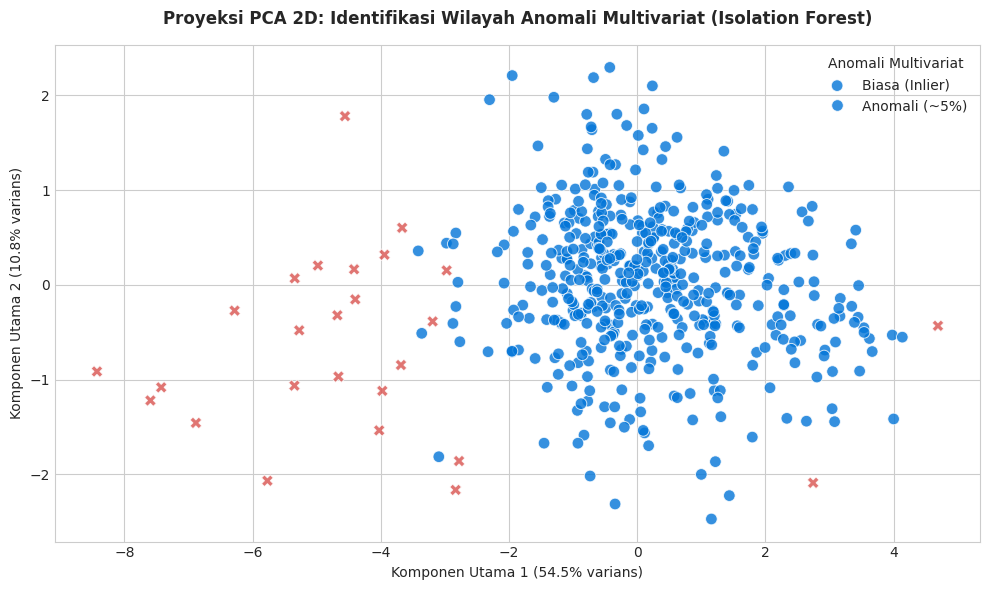


=== 15 WILAYAH DENGAN SKOR ANOMALI PALING EKSTREM ===


,provinsi,kab_kota,poverty_rate_p0,human_dev_index,sanitation_access_pct,grdp_constant_million_idr,anomaly_score
505,PAPUA,Nduga,37.180,32.840,4.350,815251,-0.201
506,PAPUA,Lanny Jaya,38.730,48.680,2.510,1202144,-0.132
507,PAPUA,Mamberamo Tengah,36.760,48.320,2.540,769368,-0.111
480,PAPUA BARAT,Tambrauw,33.860,53.710,69.750,147485,-0.086
499,PAPUA,Tolikara,32.600,49.600,3.240,1068562,-0.085
508,PAPUA,Yalimo,33.250,49.010,0.480,782619,-0.081
483,PAPUA BARAT,Pegunungan Arfak,34.700,56.130,45.210,157525,-0.074
511,PAPUA,Intan Jaya,41.660,48.340,0.360,767101,-0.071
496,PAPUA,Asmat,24.830,51.290,31.340,1563594,-0.066
509,PAPUA,Puncak,36.260,43.170,11.430,831070,-0.063


In [9]:
# 5.4 Deteksi Anomali Multivariat (Isolation Forest & PCA Projection)
socio_features = [
    'avg_school_years', 'life_expectancy', 'sanitation_access_pct',
    'clean_water_access_pct', 'expenditure_per_capita',
    'labor_participation_tpak', 'unemployment_rate_tpt'
]

X_socio = df_renamed[socio_features].copy()
X_socio['log_pdrb'] = np.log1p(df_renamed['grdp_constant_million_idr'])

# Scaling yang kebal pencilan (RobustScaler)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_socio)

# Jalankan Isolation Forest (contamination = 0.05, merepresentasikan ~5% wilayah paling menyimpang)
iso_forest = IsolationForest(contamination=0.05, random_state=RANDOM_SEED)
df_renamed['is_multivariate_anomaly'] = (iso_forest.fit_predict(X_scaled) == -1)
df_renamed['anomaly_score'] = iso_forest.decision_function(X_scaled)

n_anomalies = df_renamed['is_multivariate_anomaly'].sum()
print(f"Total wilayah terdeteksi sebagai anomali multivariat: {n_anomalies} daerah ({n_anomalies/len(df_renamed)*100:.1f}%)")

# Proyeksi 2D menggunakan PCA untuk visualisasi
pca = PCA(n_components=2, random_state=RANDOM_SEED)
pca_coords = pca.fit_transform(X_scaled)
df_renamed['pca_1'] = pca_coords[:, 0]
df_renamed['pca_2'] = pca_coords[:, 1]

# Visualisasi PCA Scatter
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_renamed, x='pca_1', y='pca_2',
    hue='is_multivariate_anomaly', palette={False: '#0275d8', True: '#d9534f'},
    style='is_multivariate_anomaly', markers={False: 'o', True: 'X'},
    s=70, alpha=0.8
)
plt.title('Proyeksi PCA 2D: Identifikasi Wilayah Anomali Multivariat (Isolation Forest)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel(f'Komponen Utama 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)')
plt.ylabel(f'Komponen Utama 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)')
plt.legend(title='Anomali Multivariat', labels=['Biasa (Inlier)', 'Anomali (~5%)'])
plt.tight_layout()
plt.show()

print("\n=== 15 WILAYAH DENGAN SKOR ANOMALI PALING EKSTREM ===")
display(df_renamed[df_renamed['is_multivariate_anomaly']].sort_values('anomaly_score')[
    ['provinsi', 'kab_kota', 'poverty_rate_p0', 'human_dev_index', 'sanitation_access_pct', 'grdp_constant_million_idr', 'anomaly_score']
].head(15))

### 5.5 Kebijakan Penanganan Outlier (*Outlier Policy*)

> [!IMPORTANT]
> **Keputusan Metodologis: JANGAN MENGHAPUS OUTLIER (*DO NOT DROP*)**
> 1. **Fakta Disparitas Riil Pembangunan Indonesia:**  
>    Outlier pada dataset ini (seperti Kabupaten Nduga dengan IPM 32.84, Intan Jaya dengan kemiskinan 41.66%, atau Kota Jakarta Pusat dengan PDRB Rp460 triliun) adalah **fakta sosiologis dan geografis nyata**, bukan kesalahan ketik (*data entry error*).
> 2. **Selaras dengan Prinsip SDGs (*Leave No One Behind*):**  
>    Menghapus daerah-daerah ini dari analisis berarti menyingkirkan wilayah yang paling membutuhkan perhatian intervensi pembangunan.
> 3. **Strategi Mitigasi pada Tahap Modeling & Clustering:**  
>    * Menggunakan **transformasi $\log(1+x)$** pada variabel berskala moneter makro (PDRB) untuk menekan kemencengan (+5.85 $\rightarrow$ +0.23).  
>    * Menggunakan **`RobustScaler`** (berbasis Median dan IQR) sebagai pengganti `StandardScaler` saat menyiapkan data untuk clustering K-Means / Hierarchical, sehingga pusat klaster tidak terdistorsi secara berlebihan oleh nilai-nilai ekstrem.

---
## 6. Analisis Multidimensi & Hubungan Antar-Indikator

Bagian ini mengeksplorasi keterkaitan antara indikator sosial-ekonomi dengan kemiskinan aktual ($P_0$):
1. **Matriks Korelasi (Pearson):** Menemukan potensi multikolinearitas antarprediktor (khususnya redundansi komponen IPM).
2. **Fenomena Pasar Tenaga Kerja:** Paradoks hubungan TPAK dan TPT terhadap kemiskinan di Indonesia.
3. **Disparitas Wilayah:** Perbandingan profil sosial-ekonomi antara Kabupaten vs Kota serta antarpulau besar menggunakan *Jittered Strip Plot*.

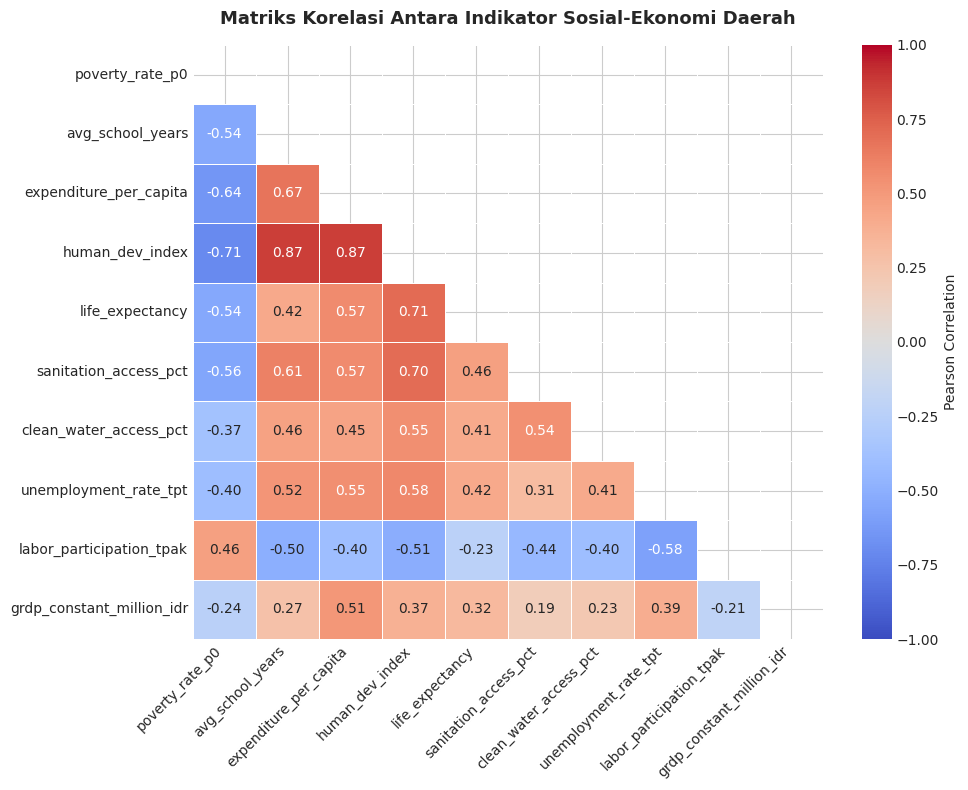


Korelasi masing-masing fitur terhadap Tingkat Kemiskinan (poverty_rate_p0):
poverty_rate_p0              1.000
labor_participation_tpak     0.462
grdp_constant_million_idr   -0.242
clean_water_access_pct      -0.374
unemployment_rate_tpt       -0.401
life_expectancy             -0.541
avg_school_years            -0.544
sanitation_access_pct       -0.562
expenditure_per_capita      -0.644
human_dev_index             -0.707
Name: poverty_rate_p0, dtype: float64

--- Bukti Multikolinearitas Komponen IPM ---
IPM <-> Pengeluaran per Kapita: 0.8715
IPM <-> Rata-rata Lama Sekolah: 0.8688
IPM <-> Umur Harapan Hidup   : 0.7071


In [10]:
# 6.1 Matriks Korelasi Indikator Sosial-Ekonomi
corr_matrix = df_renamed[numeric_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            mask=mask, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Matriks Korelasi Antara Indikator Sosial-Ekonomi Daerah', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nKorelasi masing-masing fitur terhadap Tingkat Kemiskinan (poverty_rate_p0):")
print(corr_matrix['poverty_rate_p0'].sort_values(ascending=False))

print("\n--- Bukti Multikolinearitas Komponen IPM ---")
print(f"IPM <-> Pengeluaran per Kapita: {corr_matrix.loc['human_dev_index', 'expenditure_per_capita']:.4f}")
print(f"IPM <-> Rata-rata Lama Sekolah: {corr_matrix.loc['human_dev_index', 'avg_school_years']:.4f}")
print(f"IPM <-> Umur Harapan Hidup   : {corr_matrix.loc['human_dev_index', 'life_expectancy']:.4f}")

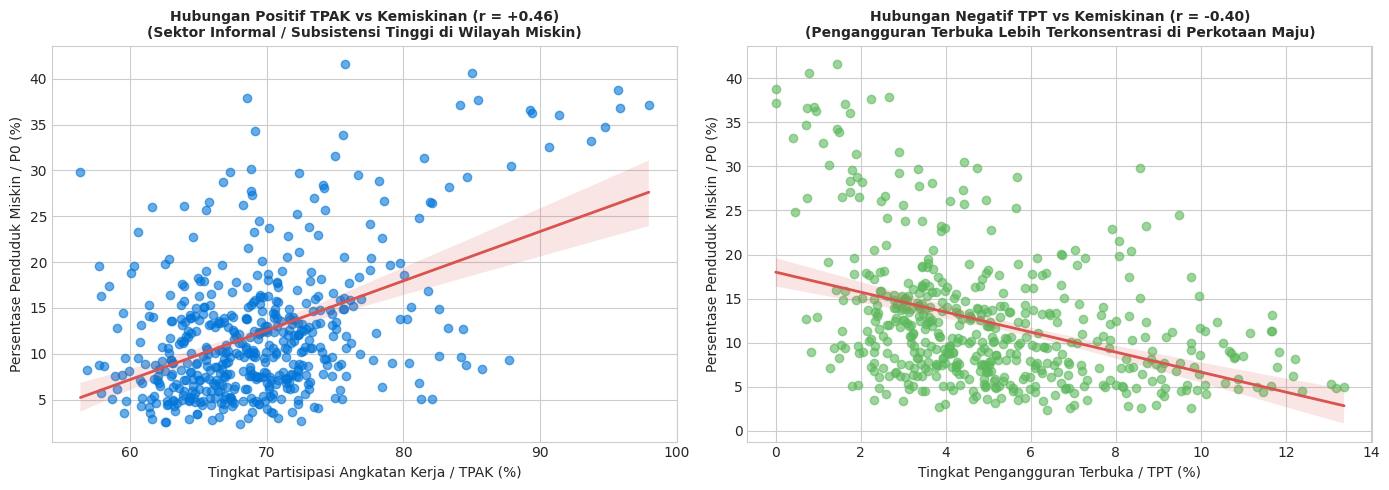

In [11]:
# 6.2 Paradoks Ketenagakerjaan: TPAK vs TPT terhadap Kemiskinan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TPAK vs Kemiskinan (Positif)
sns.regplot(data=df_renamed, x='labor_participation_tpak', y='poverty_rate_p0', ax=axes[0],
            scatter_kws={'alpha': 0.6, 'color': '#0275d8'}, line_kws={'color': '#d9534f', 'linewidth': 2})
axes[0].set_title('Hubungan Positif TPAK vs Kemiskinan (r = +0.46)\n(Sektor Informal / Subsistensi Tinggi di Wilayah Miskin)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Tingkat Partisipasi Angkatan Kerja / TPAK (%)')
axes[0].set_ylabel('Persentase Penduduk Miskin / P0 (%)')

# TPT vs Kemiskinan (Negatif)
sns.regplot(data=df_renamed, x='unemployment_rate_tpt', y='poverty_rate_p0', ax=axes[1],
            scatter_kws={'alpha': 0.6, 'color': '#5cb85c'}, line_kws={'color': '#d9534f', 'linewidth': 2})
axes[1].set_title('Hubungan Negatif TPT vs Kemiskinan (r = -0.40)\n(Pengangguran Terbuka Lebih Terkonsentrasi di Perkotaan Maju)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Tingkat Pengangguran Terbuka / TPT (%)')
axes[1].set_ylabel('Persentase Penduduk Miskin / P0 (%)')

plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_30424\2290228082.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kab_kota_comp, x='median', y='tipe_wilayah', ax=axes[0], palette=['#f0ad4e', '#5bc0de'])
C:\Users\USER\AppData\Local\Temp\ipykernel_30424\2290228082.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_renamed, x='region_pulau', y='poverty_rate_p0', order=order_islands,
C:\Users\USER\AppData\Local\Temp\ipykernel_30424\2290228082.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')


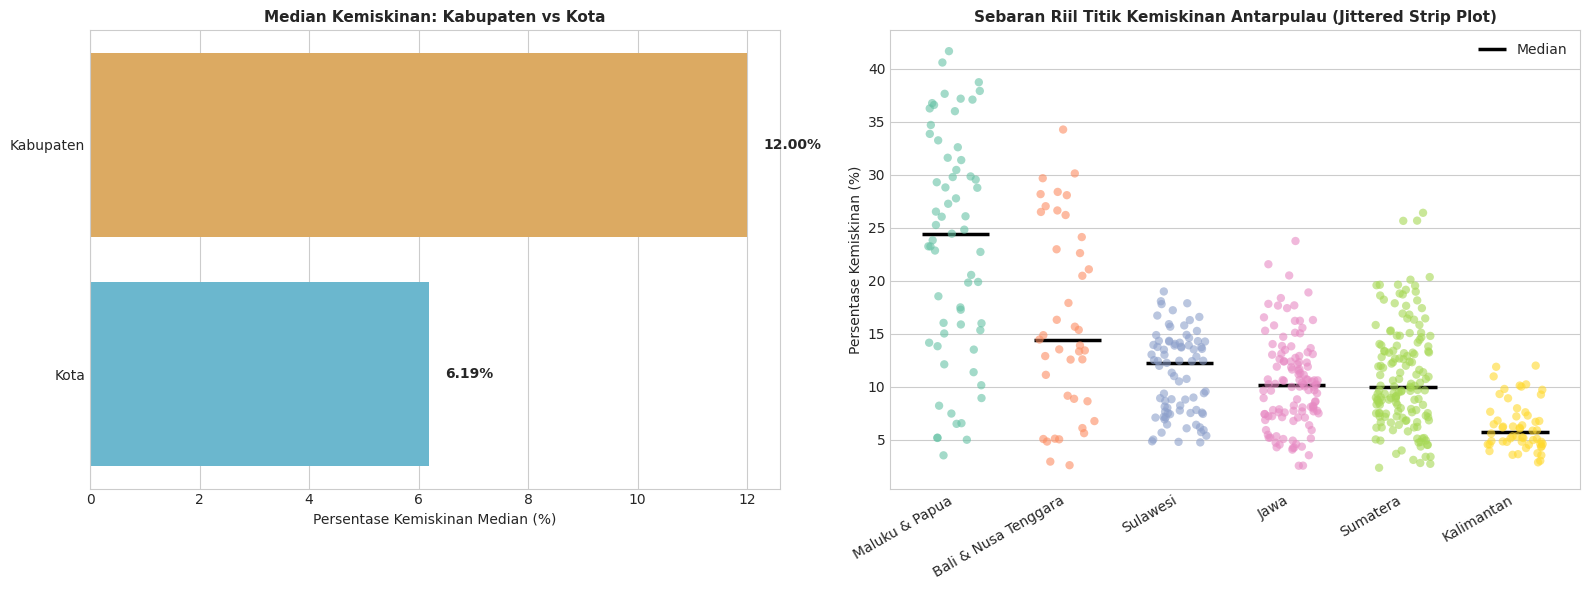

Ringkasan Statistik Disparitas Kabupaten vs Kota:


,poverty_rate_p0,human_dev_index,expenditure_per_capita,sanitation_access_pct
tipe_wilayah,,,,
Kabupaten,13.509,67.990,9540.160,74.593
Kota,7.220,77.847,13533.218,87.873


In [12]:
# 6.3 Disparitas Kabupaten vs Kota & Antar-Regional (Jittered Strip Plot)
df_renamed['tipe_wilayah'] = df_renamed['kab_kota'].apply(lambda x: 'Kota' if x.startswith('Kota') else 'Kabupaten')

def assign_island_region(prov):
    prov = prov.upper()
    if any(p in prov for p in ['ACEH', 'SUMATERA', 'RIAU', 'JAMBI', 'BENGKULU', 'LAMPUNG', 'BANGKA']):
        return 'Sumatera'
    elif any(p in prov for p in ['JAKARTA', 'JAWA', 'BANTEN', 'YOGYAKARTA']):
        return 'Jawa'
    elif any(p in prov for p in ['BALI', 'NUSA TENGGARA']):
        return 'Bali & Nusa Tenggara'
    elif 'KALIMANTAN' in prov:
        return 'Kalimantan'
    elif 'SULAWESI' in prov or 'GORONTALO' in prov:
        return 'Sulawesi'
    elif any(p in prov for p in ['MALUKU', 'PAPUA']):
        return 'Maluku & Papua'
    return 'Lainnya'

df_renamed['region_pulau'] = df_renamed['provinsi'].apply(assign_island_region)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Komparasi Kabupaten vs Kota (Horizontal Bar Chart of Medians)
kab_kota_comp = df_renamed.groupby('tipe_wilayah')['poverty_rate_p0'].agg(['median', 'mean']).reset_index()
sns.barplot(data=kab_kota_comp, x='median', y='tipe_wilayah', ax=axes[0], palette=['#f0ad4e', '#5bc0de'])
axes[0].set_title('Median Kemiskinan: Kabupaten vs Kota', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Persentase Kemiskinan Median (%)')
axes[0].set_ylabel('')
for i, v in enumerate(kab_kota_comp['median']):
    axes[0].text(v + 0.3, i, f"{v:.2f}%", va='center', fontweight='bold')

# Jittered Strip Plot Sebaran Antar-Pulau (Bebas Boxplot)
order_islands = df_renamed.groupby('region_pulau')['poverty_rate_p0'].median().sort_values(ascending=False).index
sns.stripplot(data=df_renamed, x='region_pulau', y='poverty_rate_p0', order=order_islands,
              jitter=0.25, size=6, alpha=0.6, palette='Set2', ax=axes[1])

# Tambahkan garis penanda median per pulau
island_medians = df_renamed.groupby('region_pulau')['poverty_rate_p0'].median()[order_islands]
for idx, med in enumerate(island_medians):
    axes[1].hlines(med, idx - 0.3, idx + 0.3, color='black', linewidth=2.5, label='Median' if idx == 0 else "")

axes[1].set_title('Sebaran Riil Titik Kemiskinan Antarpulau (Jittered Strip Plot)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
axes[1].set_ylabel('Persentase Kemiskinan (%)')
axes[1].set_xlabel('')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

print("Ringkasan Statistik Disparitas Kabupaten vs Kota:")
display(df_renamed.groupby('tipe_wilayah')[['poverty_rate_p0', 'human_dev_index', 'expenditure_per_capita', 'sanitation_access_pct']].mean())

---
## 7. Audit Kritis Label Target Biner (`poverty_class_target`)

Menganalisis karakteristik label target biner (0 vs 1) bawaan dataset Kaggle untuk menegaskan alasan mengapa proyek ini **TIDAK melakukan pemodelan klasifikasi terawasi (*No Supervised Classification*)**.

In [13]:
# 7.1 Distribusi Kelas Target & Bukti Inkonsistensi Pelabelan
target_counts = df_renamed['poverty_class_target'].value_counts()
target_pct = df_renamed['poverty_class_target'].value_counts(normalize=True) * 100

print("Distribusi Frekuensi Kelas Target:")
for idx, cnt in target_counts.items():
    print(f"  - Kelas {idx}: {cnt} daerah ({target_pct[idx]:.2f}%)")

# Identifikasi Anomali Label Bawaan
print("\n1. Daerah dengan P0 > 25% namun diberi label Kelas 0:")
display(df_renamed[(df_renamed['poverty_class_target'] == 0) & (df_renamed['poverty_rate_p0'] > 25)][
    ['provinsi', 'kab_kota', 'poverty_rate_p0', 'human_dev_index', 'poverty_class_target']
])

print("\n2. Daerah dengan P0 < 15% namun diberi label Kelas 1:")
display(df_renamed[(df_renamed['poverty_class_target'] == 1) & (df_renamed['poverty_rate_p0'] < 15)][
    ['provinsi', 'kab_kota', 'poverty_rate_p0', 'human_dev_index', 'poverty_class_target']
])

print("\n>> KESIMPULAN: Kolom 'poverty_class_target' tidak dijadikan target model.")
print(">> Proyek PovertyRadar SDGs sepenuhnya berfokus pada Unsupervised Clustering profil sosial-ekonomi.")

Distribusi Frekuensi Kelas Target:
  - Kelas 0: 452 daerah (87.94%)
  - Kelas 1: 62 daerah (12.06%)

1. Daerah dengan P0 > 25% namun diberi label Kelas 0:


,provinsi,kab_kota,poverty_rate_p0,human_dev_index,poverty_class_target
478,PAPUA BARAT,Sorong,27.780,65.770,0
483,PAPUA BARAT,Pegunungan Arfak,34.700,56.130,0
486,PAPUA,Jayawijaya,37.090,58.670,0



2. Daerah dengan P0 < 15% namun diberi label Kelas 1:


,provinsi,kab_kota,poverty_rate_p0,human_dev_index,poverty_class_target
485,PAPUA,Merauke,10.160,70.490,1
487,PAPUA,Jayapura,12.130,72.030,1



>> KESIMPULAN: Kolom 'poverty_class_target' tidak dijadikan target model.
>> Proyek PovertyRadar SDGs sepenuhnya berfokus pada Unsupervised Clustering profil sosial-ekonomi.


---
## 8. Export Dataset Bersih & Interim Artifacts

Menyimpan dataset olahan final yang telah diperkaya dengan penanda geografis (`tipe_wilayah`, `region_pulau`) serta fitur deteksi anomali multivariat (`is_multivariate_anomaly`, `anomaly_score`) ke folder interim.

In [14]:
# 8. Ekspor data terstandar ke data/interim/
export_cols = [
    'provinsi', 'kab_kota', 'tipe_wilayah', 'region_pulau',
    'poverty_rate_p0', 'avg_school_years', 'expenditure_per_capita',
    'human_dev_index', 'life_expectancy', 'sanitation_access_pct',
    'clean_water_access_pct', 'unemployment_rate_tpt',
    'labor_participation_tpak', 'grdp_constant_million_idr',
    'is_multivariate_anomaly', 'anomaly_score'
]

df_export = df_renamed[export_cols].copy()
df_export.to_csv(CLEANED_DATA_PATH, index=False)
print(f"Dataframe berhasil diekspor ke: {CLEANED_DATA_PATH}")
print(f"Ukuran file: {CLEANED_DATA_PATH.stat().st_size / 1024:.2f} KB | Jumlah baris: {len(df_export)} | Jumlah kolom: {len(df_export.columns)}")

Dataframe berhasil diekspor ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\data\interim\poverty_data_cleaned.csv
Ukuran file: 65.29 KB | Jumlah baris: 514 | Jumlah kolom: 16
